<h1 align="center">Sleep Digital Twin</h1>
<h2 align="center">A Data-Driven Machine Learning Simulation for Sleep Quality Prediction</h2>
<h4 align="center">Name: Hanh Le Minh Nguyen </h4>

---

## Introduction

Sleep quality is shaped by everyday lifestyle factors, including how long we sleep, how stressed we are,
how physically active we are, and our general health profile. Understanding how these factors
interact lets us make informed decisions to sleep better.

In this project, I built a simple **digital twin** of a person's sleep behavior. A digital twin
is a virtual representation of a real-world system that can be used to *simulate different
scenarios* and predict outcomes. Here, each person's lifestyle profile is their digital twin,
and we use a machine-learning model to explore **what-if** questions such as *"If this person
lowered their stress level by 2 points, how would their predicted sleep quality change?"*

**Roadmap**
1. Load and inspect the data
2. Clean the data (fix categories, parse blood pressure, check duplicates)
3. Exploratory Data Analysis (EDA) and visualization
4. Correlation analysis
5. Preprocess + train prediction models (Linear Regression & Random Forest)
6. Build the **digital twin** and run what-if simulations

*Dataset: "Sleep Health and Lifestyle Dataset" (Kaggle). Target variable: **Quality of Sleep** (scale 1–10).*


## Import libraries

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Load the dataset

In [24]:
FILENAME = "Sleep_health_and_lifestyle_dataset.csv"
df = pd.read_csv(FILENAME)
df.head()

,Person ID,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Blood Pressure,Heart Rate,Daily Steps,Sleep Disorder
0,1,Male,27,Software Engineer,6.1,6,42,6,Overweight,126/83,77,4200,None
1,2,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
2,3,Male,28,Doctor,6.2,6,60,8,Normal,125/80,75,10000,None
3,4,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea
4,5,Male,28,Sales Representative,5.9,4,30,8,Obese,140/90,85,3000,Sleep Apnea


In [25]:
print("Shape (rows, columns):", df.shape)
df.info()

Shape (rows, columns): (374, 13)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Person ID                374 non-null    int64  
 1   Gender                   374 non-null    object 
 2   Age                      374 non-null    int64  
 3   Occupation               374 non-null    object 
 4   Sleep Duration           374 non-null    float64
 5   Quality of Sleep         374 non-null    int64  
 6   Physical Activity Level  374 non-null    int64  
 7   Stress Level             374 non-null    int64  
 8   BMI Category             374 non-null    object 
 9   Blood Pressure           374 non-null    object 
 10  Heart Rate               374 non-null    int64  
 11  Daily Steps              374 non-null    int64  
 12  Sleep Disorder           374 non-null    object 
dtypes: float64(1), int64(7), object(5)
memory usage

In [26]:
# Summary statistics for numeric columns
df.describe()

,Person ID,Age,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,Heart Rate,Daily Steps
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.132086,7.312834,59.171123,5.385027,70.165775,6816.844920
std,108.108742,8.673133,0.795657,1.196956,20.830804,1.774526,4.135676,1617.915679
min,1.000000,27.000000,5.800000,4.000000,30.000000,3.000000,65.000000,3000.000000
25%,94.250000,35.250000,6.400000,6.000000,45.000000,4.000000,68.000000,5600.000000
50%,187.500000,43.000000,7.200000,7.000000,60.000000,5.000000,70.000000,7000.000000
75%,280.750000,50.000000,7.800000,8.000000,75.000000,7.000000,72.000000,8000.000000
max,374.000000,59.000000,8.500000,9.000000,90.000000,8.000000,86.000000,10000.000000


In [27]:
# Missing values per column
df.isna().sum()

Person ID                  0
Gender                     0
Age                        0
Occupation                 0
Sleep Duration             0
Quality of Sleep           0
Physical Activity Level    0
Stress Level               0
BMI Category               0
Blood Pressure             0
Heart Rate                 0
Daily Steps                0
Sleep Disorder             0
dtype: int64

### Feature summary table
A compact overview of every column: its type, missing count, and how many unique values it has.

In [28]:
feature_summary = pd.DataFrame({
    "Feature": df.columns,
    "Data Type": df.dtypes.values,
    "Missing Values": df.isna().sum().values,
    "Unique Values": df.nunique().values
})
feature_summary

,Feature,Data Type,Missing Values,Unique Values
0,Person ID,int64,0,374
1,Gender,object,0,2
2,Age,int64,0,31
3,Occupation,object,0,11
4,Sleep Duration,float64,0,27
5,Quality of Sleep,int64,0,6
6,Physical Activity Level,int64,0,16
7,Stress Level,int64,0,6
8,BMI Category,object,0,4
9,Blood Pressure,object,0,25


## Data cleaning

Before analysis we fix three data-quality issues that are specific to this dataset:

1. **`BMI Category`** contains both `"Normal"` and `"Normal Weight"` — these mean the same thing
   and should be merged into a single category.
2. **`Blood Pressure`** is stored as text like `"120/80"`. We split it into two numeric columns:
   `Systolic` and `Diastolic`.
3. **`Person ID`** is just a row identifier with no predictive value — we drop it.


### 3.1 Merge the duplicate BMI category

In [29]:
print("Before:", df["BMI Category"].unique())
df["BMI Category"] = df["BMI Category"].replace({"Normal Weight":"Normal"})
print("After: ", df["BMI Category"].unique())

Before: ['Overweight' 'Normal' 'Obese' 'Normal Weight']
After:  ['Overweight' 'Normal' 'Obese']


### 3.2 Split Blood Pressure into Systolic / Diastolic

In [68]:
if "Blood Pressure" in df.columns:
    bp = df["Blood Pressure"].str.split("/", expand=True)
    df["Systolic"]  = pd.to_numeric(bp[0])
    df["Diastolic"] = pd.to_numeric(bp[1])
    df = df.drop(columns=["Blood Pressure"])
df[["Systolic","Diastolic"]].describe()

,Systolic,Diastolic
count,374.000000,374.000000
mean,128.553476,84.649733
std,7.748118,6.161611
min,115.000000,75.000000
25%,125.000000,80.000000
50%,130.000000,85.000000
75%,135.000000,90.000000
max,142.000000,95.000000


### 3.3 Drop the ID column

In [67]:
if "Person ID" in df.columns:
    df = df.drop(columns=["Person ID"])
df.head()

,Gender,Age,Occupation,Sleep Duration,Quality of Sleep,Physical Activity Level,Stress Level,BMI Category,Heart Rate,Daily Steps,Sleep Disorder,Systolic,Diastolic
0,Male,27,Software Engineer,6.1,6,42,6,Overweight,77,4200,None,126,83
1,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
2,Male,28,Doctor,6.2,6,60,8,Normal,75,10000,None,125,80
3,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90
4,Male,28,Sales Representative,5.9,4,30,8,Obese,85,3000,Sleep Apnea,140,90


### 3.4 Check for duplicate profiles

Many rows are identical because the dataset represents grouped lifestyle profiles rather than
374 unique individuals. So I keep them since each row is still a valid observation and dropping
them would throw away most of the data, but it is important to be aware of this.


In [32]:
print("Exact duplicate rows:", df.duplicated().sum(), "out of", len(df))

Exact duplicate rows: 242 out of 374


## Hypotheses

Stating expectations before looking at the plots keeps the analysis honest. These are working hypotheses, not established causal effects:

- **Stress Level:** higher stress → lower sleep quality.
- **Sleep Duration:** longer sleep → higher sleep quality.

- **Pysical Activity Level:** higher activity level -> higher sleep quality.
- **Heart rate:** lower heart rate -> higher sleep quality.
- **Blood Pressure:** higher blood pressure -> lower sleep quality.

*These are associations within this dataset, not proof of causation.*


## Exploratory Data Analysis (EDA)
I examine the outcome distribution, numeric and categorical feature distributions, and differences in sleep quality across groups.

### 5.1 Distribution of the target: Quality of Sleep

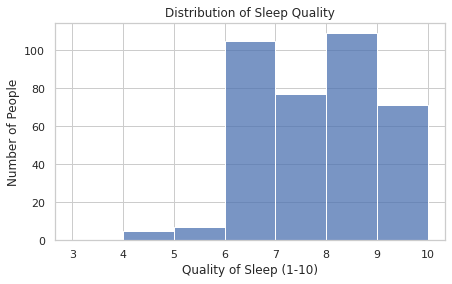

count    374.000000
mean       7.312834
std        1.196956
min        4.000000
25%        6.000000
50%        7.000000
75%        8.000000
max        9.000000
Name: Quality of Sleep, dtype: float64

In [33]:
plt.figure(figsize=(7, 4))
sns.histplot(df["Quality of Sleep"], bins=range(3, 11), kde=False)
plt.title("Distribution of Sleep Quality")
plt.xlabel("Quality of Sleep (1-10)")
plt.ylabel("Number of People")
plt.show()

df["Quality of Sleep"].describe()

### 5.2 Distributions of the key numeric features

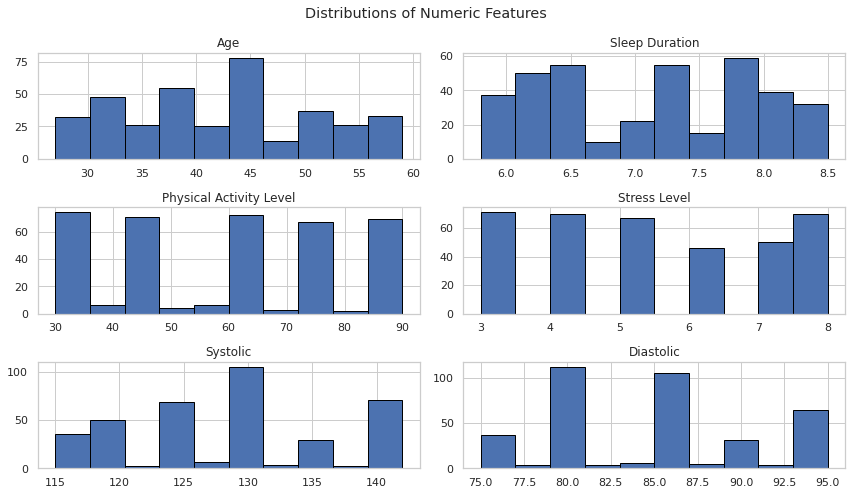

In [34]:
numeric_features = ["Age", "Sleep Duration", "Physical Activity Level",
                    "Stress Level", "Systolic", "Diastolic"]

df[numeric_features].hist(figsize=(12, 7), bins=10, edgecolor="black")
plt.suptitle("Distributions of Numeric Features")
plt.tight_layout()
plt.show()
# Y axis represents count

### Interpretation

- Physical Activity Level and Stress Level look most spread out, while the most concentrated features are Systolic (a peak near 130) and Diastolic (almost everyone is at 80 or 85–86)

- Several peaks tells me that the people in this dataset are not all alike, but are different in occupation, lifestyle to level of activities and stress, like salespeople who sleep less and are more stressed, and engineers who sleep more and are less stressed.

### 5.3 Categorical variables

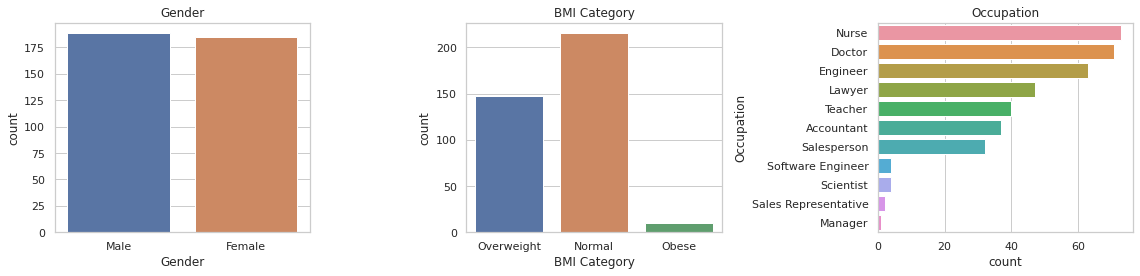

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(data=df, x="Gender", ax=axes[0])
axes[0].set_title("Gender")
sns.countplot(data=df, x="BMI Category", ax=axes[1])
axes[1].set_title("BMI Category")
sns.countplot(data=df, y="Occupation", ax=axes[2],
              order=df["Occupation"].value_counts().index)
axes[2].set_title("Occupation")
plt.tight_layout()
plt.show()

### Interpretation

- The dataset is balanced across Gender but not for Occupation
- If one occupation dominates the data, the model will has almost no examples for rare occupation, so it can’t learn what is specific to that job. It will likely fall back on patterns from the big occupations, meaning its predictions are really extrapolation. Therefore, they can be biased and much less reliable.

### 5.4 Sleep quality by category

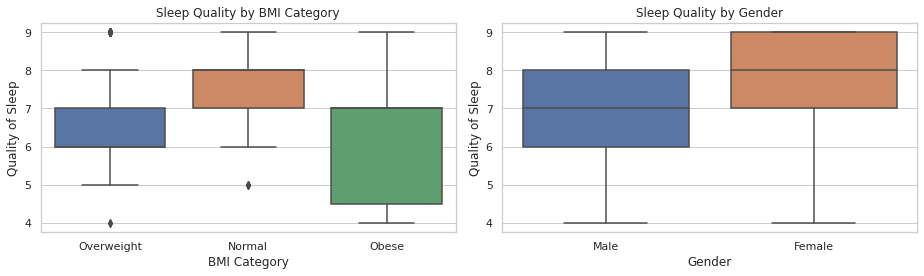

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="BMI Category", y="Quality of Sleep", ax=axes[0])
axes[0].set_title("Sleep Quality by BMI Category")
sns.boxplot(data=df, x="Gender", y="Quality of Sleep", ax=axes[1])
axes[1].set_title("Sleep Quality by Gender")
plt.tight_layout()
plt.show()

## Correlation analysis
I examine pairwise linear associations between numerical features and sleep quality. Correlation describes association, not causal impact.

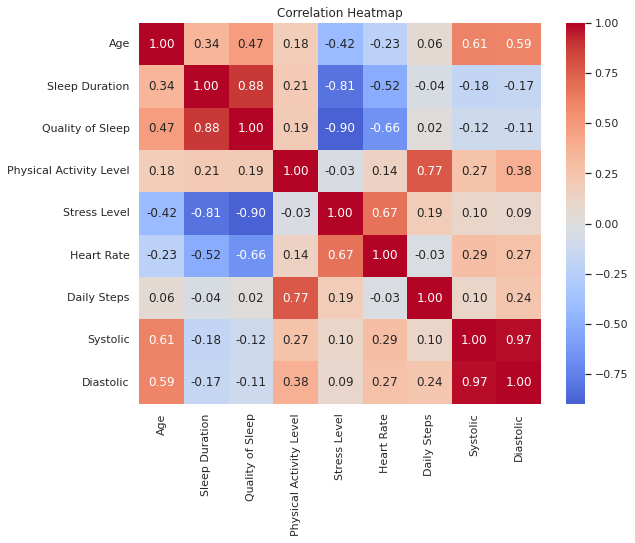

In [37]:
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap")
plt.show()

In [45]:
# Correlation of every numeric feature with the target, sorted
corr["Quality of Sleep"].drop("Quality of Sleep").sort_values(ascending=False)

Sleep Duration             0.883213
Age                        0.473734
Physical Activity Level    0.192896
Daily Steps                0.016791
Diastolic                 -0.110151
Systolic                  -0.121632
Heart Rate                -0.659865
Stress Level              -0.898752
Name: Quality of Sleep, dtype: float64

### Interpretation

The correlation table shows `Stress Level` at roughly **-0.90** with sleep quality and
`Sleep Duration` at roughly **+0.88**.

- The digital twin should focus on Stress Level (r ≈ -0.90) and Sleep Duration (r ≈ +0.88). They have the strongest negative relationships with sleep quality, far above the other features, and unlike Age or Gender they are things a person can change, so they make useful levers for what-if simulations.

Note: Poor sleep could raise stress (reverse causation), the two could reinforce each other, or a third factor such as occupation, workload, or a sleep disorder could drive both. The data is also observational and contains many duplicate profiles. Showing that stress causes poor sleep would need a controlled experiment or a causal analysis.

## Preprocessing & model training

I predict **Quality of Sleep** from the lifestyle and health features. Steps:

- Separate features `X` from the target `y`.
- Build a preprocessing pipeline: **one-hot encode** categorical columns and **standardize**
  numeric columns.
- Split into train/test sets (80/20) so we can evaluate on data the model never saw.
- Train two models:
  - **Linear Regression** — highly interpretable; its coefficients are the "levers."
  - **Random Forest** — usually more accurate; captures non-linear effects.

In [51]:
# Numeric and categorical columns need different treatment before modelling.

target = "Quality of Sleep"
X = df.drop(columns=[target])
y = df[target]

categorical_cols = ["Gender", "Occupation", "BMI Category", "Sleep Disorder"]
numeric_cols = [c for c in X.columns if c not in categorical_cols]

print("Numeric features:    ", numeric_cols)
print("Categorical features:", categorical_cols)

from sklearn.impute import SimpleImputer

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="None"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

Numeric features:     ['Age', 'Sleep Duration', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps', 'Systolic', 'Diastolic']
Categorical features: ['Gender', 'Occupation', 'BMI Category', 'Sleep Disorder']


In [52]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])

Train size: 299  Test size: 75


### 7.1 Train and compare the two models

In [53]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
}

results = {}
for name, estimator in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", estimator)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_test)
    results[name] = {
        "pipeline": pipe,
        "R2":  r2_score(y_test, preds),
        "MAE": mean_absolute_error(y_test, preds),
    }
    print(f"{name:20s}  R2 = {results[name]['R2']:.3f}   MAE = {results[name]['MAE']:.3f}")

Linear Regression     R2 = 0.966   MAE = 0.120
Random Forest         R2 = 0.986   MAE = 0.042


**How to read this:** R² is the fraction of variation in sleep quality the model explains
(1.0 = perfect). MAE is the average error in sleep-quality points. Both models should score well
here because the data has genuine signal.

### Interpretation

- Many rows in this dataset are exact duplicates (see Step 3.4), since the data represents grouped lifestyle profiles rather than unique individuals. A random split puts copies of the same profile in both the training and test sets, so the model is effectively tested on data it has already seen. It can score well by memorizing profiles instead of learning patterns that generalize, so R² is inflated. This is data leakage.

- Use a group-based split, such as GroupShuffleSplit, so that identical profiles stay together in either train or test. Removing duplicate rows before splitting would also help. The test set would then contain only unseen profiles, giving a more realistic score.
>

### 7.2 Which features matter most? (Random Forest importances)

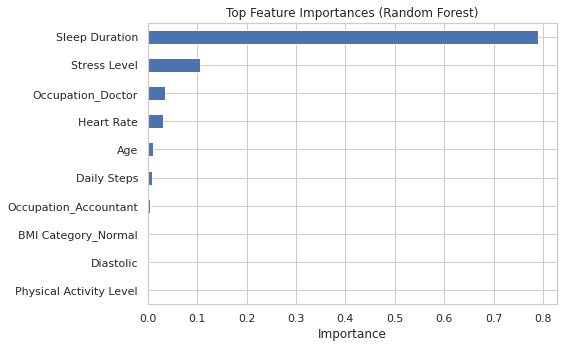

In [54]:
best_pipe = results["Random Forest"]["pipeline"]

# Recover feature names after one-hot encoding
ohe = best_pipe.named_steps["prep"].named_transformers_["cat"]
feature_names = numeric_cols + list(ohe.get_feature_names_out(categorical_cols))
importances = best_pipe.named_steps["model"].feature_importances_

imp = (pd.Series(importances, index=feature_names)
         .sort_values(ascending=True)
         .tail(10))

plt.figure(figsize=(8, 5))
imp.plot(kind="barh")
plt.title("Top Feature Importances (Random Forest)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## The Digital Twin: what-if simulation

Now the payoff. I select a dataset profile as a fixed virtual representation and change selected inputs to compare model predictions. These what-if outputs are associative model predictions, not validated causal effects.

I use the **Random Forest** pipeline as the twin's "engine." The helper below takes a base profile plus a dictionary of changes, and returns the new predicted sleep quality.


In [55]:
twin_model = results["Random Forest"]["pipeline"]

def predict_quality(profile: dict) -> float:
    """Predict sleep quality for a single profile given as a dict of feature -> value."""
    row = pd.DataFrame([profile])[X.columns]   # keep original column order
    # The pipeline automatically handles preprocessing and predicting in one go
    row["Sleep Disorder"] = row["Sleep Disorder"].fillna("None") #explicit label
    return float(twin_model.predict(row)[0])

def simulate(base_profile: dict, changes: dict) -> dict:
    """Apply `changes` to `base_profile` and report the effect on predicted sleep quality."""
    new_profile = {**base_profile, **changes}
    base_pred = predict_quality(base_profile)
    new_pred  = predict_quality(new_profile)
    return {
        "changes": changes,
        "baseline_quality": round(base_pred, 2),
        "new_quality":      round(new_pred, 2),
        "delta":            round(new_pred - base_pred, 2),
    }

### 8.1 Pick a digital twin
I use the first dataset profile as an illustrative twin. The prediction uses the already fitted model pipeline; there is no need to refit preprocessing separately.

In [56]:
# Fit the preprocessor on the training data so that it can be used for transforming individual profiles
preprocess.fit(X_train)

# Take one real person from the dataset as our twin
twin = X.iloc[0].to_dict()
print("Digital twin profile:")
for k, v in twin.items():
    print(f"  {k:26s}: {v}")
print(f"\nActual sleep quality in data : {y.iloc[0]}")
print(f"Model predicted sleep quality: {predict_quality(twin):.2f}")

Digital twin profile:
  Gender                    : Male
  Age                       : 27
  Occupation                : Software Engineer
  Sleep Duration            : 6.1
  Physical Activity Level   : 42
  Stress Level              : 6
  BMI Category              : Overweight
  Heart Rate                : 77
  Daily Steps               : 4200
  Sleep Disorder            : None
  Systolic                  : 126
  Diastolic                 : 83

Actual sleep quality in data : 6
Model predicted sleep quality: 5.88


### 8.2 Single what-if scenarios
I change stress, sleep duration, and heart rate one at a time, keeping other profile attributes fixed.

In [57]:
scenarios = [
    {"Stress Level": twin["Stress Level"] - 2},          # lower stress by 2
    {"Sleep Duration": twin["Sleep Duration"] + 1},      # sleep 1 hour more
    {"Heart Rate":twin["Heart Rate"] +3},                # increase heart rate by 3
]
for s in scenarios:
    out = simulate(twin, s)
    print(f"Change {out['changes']}")
    print(f"   {out['baseline_quality']}  ->  {out['new_quality']}   (delta {out['delta']:+.2f})\n")

Change {'Stress Level': 4}
   5.88  ->  6.58   (delta +0.70)

Change {'Sleep Duration': 7.1}
   5.88  ->  7.16   (delta +1.28)

Change {'Heart Rate': 80}
   5.88  ->  5.39   (delta -0.49)



### 8.3 Combined a full lifestyle intervention
This example changes several lifestyle inputs together. Its output is a hypothetical model prediction, not a recommended treatment.

In [62]:
combo = {
    "Stress Level": max(1, twin["Stress Level"] - 3),
    "Sleep Duration": twin["Sleep Duration"] + 1.0,
    "Physical Activity Level": twin["Physical Activity Level"] + 30,
}
out = simulate(twin, combo)
print("Combined intervention:", out["changes"])
print(f"Predicted sleep quality: {out['baseline_quality']}  ->  {out['new_quality']}  (delta {out['delta']:+.2f})")

Combined intervention: {'Stress Level': 3, 'Sleep Duration': 7.1, 'Physical Activity Level': 72}
Predicted sleep quality: 5.88  ->  7.47  (delta +1.59)


### 8.4 Sensitivity Sweeps
I vary one input over a range while holding other features constant. The resulting curves reveal how the fitted Random Forest responds to those hypothetical changes.


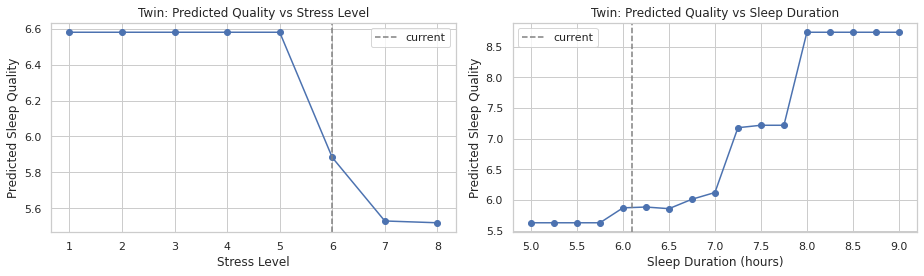

In [59]:
# A sweep asks the same what-if question many times across a whole range of values.

def sweep(base_profile: dict, feature: str, values):
    preds = []
    for v in values:
        p = {**base_profile, feature: v}
        preds.append(predict_quality(p))
    return list(values), preds

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

stress_vals = range(1, 9)
xs, ys = sweep(twin, "Stress Level", stress_vals)
axes[0].plot(xs, ys, marker="o")
axes[0].axvline(twin["Stress Level"], ls="--", color="gray", label="current")
axes[0].set(title="Twin: Predicted Quality vs Stress Level",
            xlabel="Stress Level", ylabel="Predicted Sleep Quality")
axes[0].legend()

dur_vals = np.arange(5.0, 9.1, 0.25)
xs, ys = sweep(twin, "Sleep Duration", dur_vals)
axes[1].plot(xs, ys, marker="o")
axes[1].axvline(twin["Sleep Duration"], ls="--", color="gray", label="current")
axes[1].set(title="Twin: Predicted Quality vs Sleep Duration",
            xlabel="Sleep Duration (hours)", ylabel="Predicted Sleep Quality")
axes[1].legend()

plt.tight_layout()
plt.show()

### Interpretation

- Both plotted curves match your hypotheses: predicted quality falls as stress rises (flat until 5, then dropping to about 5.5) and rises with sleep duration (about 5.6 at 5 hours up to about 8.75 at 8 hours and beyond).

- A Random Forest averages decision trees that predict by threshold splits, so every input in the same leaf gets the same value. I think the Linear Regression twin would not look the same since it predicts a weighted sum of features so each curve should be a smooth straight line.

### 8.5 Compare two different twins

In [64]:
# The same intervention does not help every twin equally. 
# Compare the same stress change for two baseline profiles.

high_stress_twin = X[X["Stress Level"]>=8].iloc[0].to_dict()

for label, t in [("Twin A (row 0)", twin), ("Twin B (high stress)", high_stress_twin)]:
    base = predict_quality(t)
    relaxed = predict_quality({**t, "Stress Level": max(1, t["Stress Level"] - 2)})
    print(f"{label}: stress={t['Stress Level']}, baseline quality={base:.2f}, "
          f"after -2 stress={relaxed:.2f} (delta {relaxed-base:+.2f})")

Twin A (row 0): stress=6, baseline quality=5.88, after -2 stress=6.58 (delta +0.70)
Twin B (high stress): stress=8, baseline quality=6.00, after -2 stress=6.15 (delta +0.15)


### Wrapping up

**What simulation adds**. A prediction model estimates sleep quality for a given profile. The simulate() function compares predictions for that same profile before and after a hypothetical input change. 

**What a continuously updated twin would need and gain**. With a reliable data pipeline, it could maintain a changing personal history, refresh predictions as new observations arrive, detect unusual or worsening trends, and compare earlier what-if predictions with later observed sleep patterns. It could also help assess when the model needs recalibration. The current notebook instead uses a fixed dataset profile and does not learn from live readings.

**Note**: Duplicate lifestyle profiles may inflate test performance, and model associations do not establish causal effects. Clinical decisions require appropriately validated evidence and qualified healthcare professionals.

## Conclusion & next steps

This project demonstrates a complete workflow: data cleaning, exploratory analysis, correlation assessment, preprocessing, trainning and comparing two machine learning models Linear Regression and Random Forest, and profile-based what-if simulations.

**Key findings & Limitations**
- In this dataset, stress level and sleep duration show strong associations with reported sleep quality.
- The simulation allows comparisons between predicted outcomes under alternative profile inputs; these differences are not causal treatment effects.
- Duplicate profiles can inflate random-split performance, limiting confidence in generalization to truly unseen individuals.

**Next extensions**
- Add confidence/uncertainty to the twin's predictions (e.g. prediction intervals).
- Turn `simulate()` into an interactive widget with sliders (`ipywidgets`) for a live demo.
- Try gradient boosting (XGBoost / LightGBM) and compare.
- Validate the twin's counterfactuals against sleep-science literature.
- Test real-time data ingestion and longitudinal model monitoring before describing this as a continuously updating twin.

**Caveat.** The model captures *associations* in this dataset, not proven causation. Many rows are
identical lifestyle profiles, so real-world generalization is limited — the goal here is to
demonstrate the digital-twin *methodology*.

Data source: Sleep Health and Lifestyle Dataset (Kaggle). This project is an educational prototype, not a medical device or clinical decision system.